In [6]:
from langgraph.graph import StateGraph,END
import random
from typing import List, Dict, TypedDict

In [7]:
class AgentState(TypedDict):
    number: int 
    counter: int
    guess: int

In [8]:
def setup(state: AgentState) -> AgentState:
    state["counter"] = 0
    state["guess"] = 0
    return state

def guess(state: AgentState) -> AgentState:
    state["counter"] += 1
    state["guess"] = random.randint(1, 10)
    return state

def should_continue(state: AgentState) -> str:
    """this function determines whether the guessing should continue or exit based on the current guess."""
    if state["guess"] == state["number"]:
        return "exit"
    return "loop"



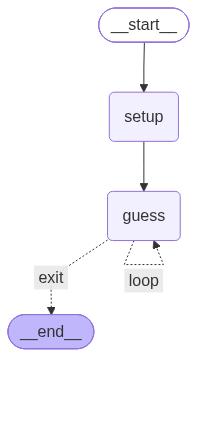

In [13]:
graph = StateGraph(AgentState)

graph.add_node("setup", setup)
graph.add_node("guess", guess)
graph.add_edge("setup", "guess")

graph.add_conditional_edges("guess", should_continue,{"loop": "guess", "exit": END})
graph.set_entry_point("setup")
app = graph.compile()
from IPython.display import display
display(app)

In [14]:
app.invoke({"number": 5})

{'number': 5, 'counter': 4, 'guess': 5}